# CMPS458 — Reinforcement Learning | Assignment 2
**Karim Tarek Abdalla**  
**Ziad Abdelraouf Hassan**


## Requirements


In [14]:
# Uncomment this line once if your environment needs the dependencies:
# %pip install -U gymnasium pygame numpy matplotlib "imageio[ffmpeg]" moviepy


## Imports


In [15]:
import os
import time
from typing import Optional, Dict, Tuple, Any

import gymnasium as gym
from gymnasium import spaces
from gymnasium.wrappers import RecordVideo
import numpy as np
import pygame
import matplotlib.pyplot as plt

print(f"Gymnasium version: {gym.__version__}")
print(f"NumPy version:     {np.__version__}")
print(f"Pygame version:    {pygame.__version__}")

Gymnasium version: 1.4.0
NumPy version:     2.5.4
Pygame version:    2.6.1


## Environment


In [ ]:
class CustomGridMazeEnv(gym.Env):
    metadata = {
        "render_modes": ["human", "rgb_array"],
        "render_fps": 4,
    }

    def __init__(self, size: int = 5, render_mode: Optional[str] = None):
        super().__init__()
        self.size = size
        self.render_mode = render_mode
        self.cell_size = 100
        self.window_size = self.size * self.cell_size
        self.window = None
        self.clock = None

        # Internal coordinates:
        self._agent_location = np.array([-1, -1], dtype=np.int32)
        self._target_location = np.array([-1, -1], dtype=np.int32)
        self._obstacle_locations = np.empty((2, 2), dtype=np.int32)
        self._layout_initialized = False
        self.P: Dict[int, Dict[int, list]] = {}

        self.observation_space = spaces.Dict(
            {
                "agent": spaces.Box(0, size - 1, shape=(2,), dtype=np.int32),
                "target": spaces.Box(0, size - 1, shape=(2,), dtype=np.int32),
                "obstacles": spaces.Box(0, size - 1, shape=(2, 2), dtype=np.int32),
            }
        )

        
        self.action_space = spaces.Discrete(4)
        self._action_to_direction = {
            0: np.array([0, 1]),   
            1: np.array([-1, 0]),  
            2: np.array([0, -1]),  
            3: np.array([1, 0]),   
        }

    def pos_to_state(self, pos) -> int:
        """Maps 2d into 1d index s = row * size + col."""
        return int(pos[0] * self.size + pos[1])

    def state_to_pos(self, state: int) -> np.ndarray:
        """Maps 1d back to 2d"""
        return np.array(divmod(int(state), self.size), dtype=np.int32)

    def generate_maze(self):
        """Samples 1 target and 2 distinct obstacles, then builds the transition table P."""
        cells = self.np_random.choice(self.size * self.size, size=3, replace=False)
        self._target_location = self.state_to_pos(cells[0])
        self._obstacle_locations = np.array(
            [self.state_to_pos(cells[1]), self.state_to_pos(cells[2])], dtype=np.int32
        )
        self._layout_initialized = True
        self._build_transition_table()

    def _build_transition_table(self):
        """Constructs transition table self.P[s][a] = [(prob, next_s, reward, terminated)]."""
        self.P = {s: {a: [] for a in range(self.action_space.n)} for s in range(self.size * self.size)}
        target_state = self.pos_to_state(self._target_location)
        obstacle_states = {self.pos_to_state(obs) for obs in self._obstacle_locations}

        for s in range(self.size * self.size):
            pos = self.state_to_pos(s)
            for a in range(self.action_space.n):
                if s == target_state or s in obstacle_states:
                    self.P[s][a] = [(1.0, s, 0.0, True)]
                else:
                    next_pos = np.clip(pos + self._action_to_direction[a], 0, self.size - 1)
                    next_s = self.pos_to_state(next_pos)
                    if next_s == target_state:
                        self.P[s][a] = [(1.0, next_s, 1.0, True)]
                    elif next_s in obstacle_states:
                        self.P[s][a] = [(1.0, next_s, -1.0, True)]
                    else:
                        self.P[s][a] = [(1.0, next_s, 0.0, False)]

    def _get_obs(self) -> Dict[str, np.ndarray]:
        return {
            "agent": self._agent_location.copy(),
            "target": self._target_location.copy(),
            "obstacles": self._obstacle_locations.copy(),
        }

    def _get_info(self) -> Dict[str, Any]:
        return {
            "distance": float(np.linalg.norm(self._agent_location - self._target_location, ord=1))
        }

    def reset(self, seed: Optional[int] = None, options: Optional[dict] = None):
        super().reset(seed=seed)
        new_layout = options.get("new_layout", False) if options else False

        # Generate new layout only if uninitialized 
        if not self._layout_initialized or new_layout:
            self.generate_maze()

        occupied = {
            self.pos_to_state(self._target_location),
            self.pos_to_state(self._obstacle_locations[0]),
            self.pos_to_state(self._obstacle_locations[1]),
        }
        empty_cells = [c for c in range(self.size * self.size) if c not in occupied]
        start_cell = self.np_random.choice(empty_cells)
        self._agent_location = self.state_to_pos(start_cell)

        return self._get_obs(), self._get_info()

    def step(self, action: int):
        direction = self._action_to_direction[action]
        self._agent_location = np.clip(self._agent_location + direction, 0, self.size - 1)

        hits_obstacle = any(
            np.array_equal(self._agent_location, obs) for obs in self._obstacle_locations
        )
        if hits_obstacle:
            terminated = True
            reward = -1.0
        else:
            terminated = bool(np.array_equal(self._agent_location, self._target_location))
            reward = 1.0 if terminated else 0.0

        return self._get_obs(), reward, terminated, False, self._get_info()

    def render(self):
        if self.render_mode is None:
            return None

        if self.window is None and self.render_mode == "human":
            pygame.init()
            pygame.display.init()
            self.window = pygame.display.set_mode((self.window_size, self.window_size))
            pygame.display.set_caption("Grid Maze")

        if self.clock is None and self.render_mode == "human":
            self.clock = pygame.time.Clock()

        canvas = pygame.Surface((self.window_size, self.window_size))
        canvas.fill((255, 255, 255))

        for obs in self._obstacle_locations:
            rect = pygame.Rect(
                obs[1] * self.cell_size,
                obs[0] * self.cell_size,
                self.cell_size,
                self.cell_size,
            )
            pygame.draw.rect(canvas, (220, 60, 60), rect)

        # Draw Target (Green square)
        target_rect = pygame.Rect(
            self._target_location[1] * self.cell_size,
            self._target_location[0] * self.cell_size,
            self.cell_size,
            self.cell_size,
        )
        pygame.draw.rect(canvas, (60, 200, 60), target_rect)

        # Draw Agent (Blue circle)
        agent_center = (
            int((self._agent_location[1] + 0.5) * self.cell_size),
            int((self._agent_location[0] + 0.5) * self.cell_size),
        )
        pygame.draw.circle(canvas, (50, 110, 240), agent_center, int(self.cell_size * 0.35))

        # Draw Grid Lines
        for i in range(self.size + 1):
            pygame.draw.line(canvas, (210, 210, 210), (0, i * self.cell_size), (self.window_size, i * self.cell_size), 2)
            pygame.draw.line(canvas, (210, 210, 210), (i * self.cell_size, 0), (i * self.cell_size, self.window_size), 2)

        if self.render_mode == "human":
            self.window.blit(canvas, (0, 0))
            pygame.event.pump()
            pygame.display.update()
            self.clock.tick(self.metadata["render_fps"])
        elif self.render_mode == "rgb_array":
            return np.transpose(np.array(pygame.surfarray.pixels3d(canvas)), axes=(1, 0, 2))

    def close(self):
        if self.window is not None:
            pygame.display.quit()
            pygame.quit()
            self.window = None
            self.clock = None

## Maze Setup


In [17]:
SEED = 38
GAMMA = 0.95
THETA = 1e-10

# No human window during computation; render only to an RGB image if needed.
env = CustomGridMazeEnv(size=5, render_mode="rgb_array")
observation, info = env.reset(seed=SEED)
n_states = env.size ** 2
n_actions = env.action_space.n
terminal_states = {env.pos_to_state(env._target_location)} | {
    env.pos_to_state(p) for p in env._obstacle_locations
}
print("Maze shape:", env.size, "x", env.size)
print("Starting cell:", tuple(observation["agent"]))
print("Goal cell:", tuple(observation["target"]))
print("Bad cells:", [tuple(x) for x in observation["obstacles"]])
print("Number of positional states:", n_states)
print("Number of actions:", n_actions)
print("Terminal states:", sorted(terminal_states))
assert len(env.P) == n_states
assert all(len(env.P[s]) == n_actions for s in range(n_states))


Maze shape: 5 x 5
Starting cell: (np.int32(3), np.int32(3))
Goal cell: (np.int32(2), np.int32(1))
Bad cells: [(np.int32(1), np.int32(3)), (np.int32(1), np.int32(0))]
Number of positional states: 25
Number of actions: 4
Terminal states: [5, 8, 11]


## Policy Evaluation


In [18]:
def action_value(P, V, state, action, gamma=0.95):
    """Expected one-step Bellman return from (state, action)."""
    return sum(
        probability * (reward + (0.0 if done else gamma * V[next_state]))
        for probability, next_state, reward, done in P[state][action]
    )


def policy_evaluation(policy, P, n_states, n_actions, gamma=0.95,
                      theta=1e-10, max_sweeps=10000, V_init=None):
    """Evaluate a stochastic policy by in-place iterative sweeps."""
    V = np.zeros(n_states, dtype=float) if V_init is None else V_init.copy()
    for sweep in range(1, max_sweeps + 1):
        delta = 0.0
        for state in range(n_states):
            old_value = V[state]
            V[state] = sum(
                policy[state, action] * action_value(P, V, state, action, gamma)
                for action in range(n_actions)
            )
            delta = max(delta, abs(old_value - V[state]))
        if delta < theta:
            return V, sweep
    raise RuntimeError("Policy evaluation did not converge; check gamma/theta.")


## Policy Iteration


In [ ]:
def policy_improvement(V, P, n_states, n_actions, gamma=0.95):
    """Return a deterministic greedy policy and the Q(s,a) table."""
    Q = np.zeros((n_states, n_actions), dtype=float)
    improved_policy = np.zeros((n_states, n_actions), dtype=float)
    for state in range(n_states):
        for action in range(n_actions):
            Q[state, action] = action_value(P, V, state, action, gamma)
        best_action = int(np.argmax(Q[state]))
        improved_policy[state, best_action] = 1.0
    return improved_policy, Q


def policy_iteration(P, n_states, n_actions, gamma=0.95, theta=1e-10,
                     max_policy_iterations=1000, max_eval_sweeps=10000):
    """Classical policy iteration for the given *fixed* transition table."""
    policy = np.full((n_states, n_actions), 1.0 / n_actions, dtype=float)
    V = np.zeros(n_states, dtype=float)
    total_evaluation_sweeps = 0
    history = []
    for iteration in range(1, max_policy_iterations + 1):
        V, sweeps = policy_evaluation(
            policy, P, n_states, n_actions, gamma, theta, max_eval_sweeps, V
        )
        total_evaluation_sweeps += sweeps
        improved_policy, Q = policy_improvement(V, P, n_states, n_actions, gamma)
        old_actions = np.argmax(policy, axis=1)
        new_actions = np.argmax(improved_policy, axis=1)
   
        stable = bool(np.array_equal(policy, improved_policy))
        changed = int(np.sum(old_actions != new_actions))
        history.append({"iteration": iteration, "evaluation_sweeps": sweeps,
                        "changed_greedy_actions": changed, "stable": stable})
        policy = improved_policy
        if stable:
            V, last_sweeps = policy_evaluation(
                policy, P, n_states, n_actions, gamma, theta, max_eval_sweeps, V
            )
            total_evaluation_sweeps += last_sweeps
            return policy, V, Q, history, total_evaluation_sweeps
    raise RuntimeError("Policy iteration did not reach a stable policy.")


## Training


In [20]:
policy, V, Q, history, total_sweeps = policy_iteration(
    env.P, n_states, n_actions, gamma=GAMMA, theta=THETA
)
print(f"Policy improvement iterations until stable: {len(history)}")
print(f"Total policy-evaluation sweeps (including final evaluation): {total_sweeps}")
for item in history:
    print(item)
print("Final value function (rounded):")
print(np.round(V.reshape(env.size, env.size), 3))
assert history[-1]["stable"]
assert np.isfinite(V).all()
assert np.allclose(policy.sum(axis=1), 1.0)


Policy improvement iterations until stable: 4
Total policy-evaluation sweeps (including final evaluation): 495
{'iteration': 1, 'evaluation_sweeps': 109, 'changed_greedy_actions': 17, 'stable': False}
{'iteration': 2, 'evaluation_sweeps': 381, 'changed_greedy_actions': 9, 'stable': False}
{'iteration': 3, 'evaluation_sweeps': 3, 'changed_greedy_actions': 2, 'stable': False}
{'iteration': 4, 'evaluation_sweeps': 1, 'changed_greedy_actions': 0, 'stable': True}
Final value function (rounded):
[[0.902 0.95  0.902 0.857 0.815]
 [0.    1.    0.95  0.    0.857]
 [1.    0.    1.    0.95  0.902]
 [0.95  1.    0.95  0.902 0.857]
 [0.902 0.95  0.902 0.857 0.815]]


## Policy Visualization


 →   ↓   ←   ←   ← 
 X   ↓   ←   X   ↓ 
 →   G   ←   ←   ← 
 →   ↑   ↑   ↑   ↑ 
 →   ↑   ↑   ↑   ↑ 

Value grid:
[[0.902 0.95  0.902 0.857 0.815]
 [0.    1.    0.95  0.    0.857]
 [1.    0.    1.    0.95  0.902]
 [0.95  1.    0.95  0.902 0.857]
 [0.902 0.95  0.902 0.857 0.815]]


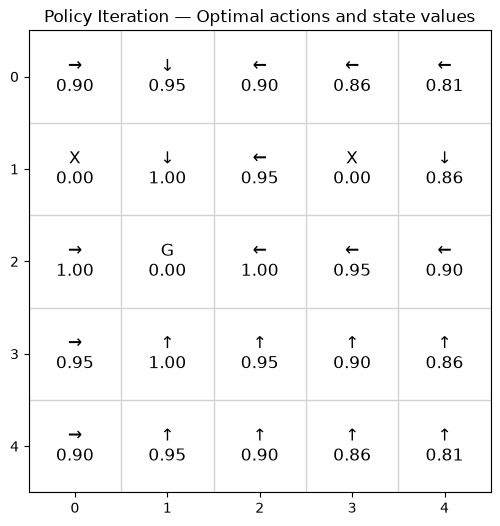

In [21]:
ARROWS = {0: "→", 1: "↑", 2: "←", 3: "↓"}

def print_policy_grid(env, policy, V=None):
    goal = env.pos_to_state(env._target_location)
    bad = {env.pos_to_state(p) for p in env._obstacle_locations}
    for row in range(env.size):
        symbols = []
        for col in range(env.size):
            s = row * env.size + col
            symbol = " G " if s == goal else " X " if s in bad else f" {ARROWS[int(np.argmax(policy[s]))]} "
            symbols.append(symbol)
        print(" ".join(symbols))
    if V is not None:
        print("\nValue grid:")
        print(np.round(V.reshape(env.size, env.size), 3))

print_policy_grid(env, policy, V)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(np.zeros((env.size, env.size)), cmap="Greys", vmin=0, vmax=1)
for s in range(n_states):
    row, col = divmod(s, env.size)
    if s == env.pos_to_state(env._target_location):
        label = "G"
    elif s in terminal_states:
        label = "X"
    else:
        label = ARROWS[int(np.argmax(policy[s]))]
    ax.text(col, row, f"{label}\n{V[s]:.2f}", ha="center", va="center", fontsize=12)
ax.set_xticks(range(env.size))
ax.set_yticks(range(env.size))
ax.set_xticks(np.arange(-0.5, env.size, 1), minor=True)
ax.set_yticks(np.arange(-0.5, env.size, 1), minor=True)
ax.grid(which="minor", color="lightgray", linewidth=1)
ax.tick_params(which="minor", bottom=False, left=False)
ax.set_title("Policy Iteration — Optimal actions and state values")
plt.show()


## Evaluation


In [22]:
def rollout_from_state(env, policy, start_state, max_steps=100):
    """Force a start position for testing without regenerating the maze."""
    env._agent_location = env.state_to_pos(start_state)
    trajectory = [int(start_state)]
    reward = 0.0
    terminated = False
    truncated = False
    for step in range(1, max_steps + 1):
        state = env.pos_to_state(env._agent_location)
        action = int(np.argmax(policy[state]))
        obs, reward, terminated, truncated, info = env.step(action)
        trajectory.append(env.pos_to_state(env._agent_location))
        if terminated or truncated:
            return {"start": int(start_state), "success": bool(terminated and reward > 0),
                    "steps": step, "reward": float(reward), "path": trajectory}
    return {"start": int(start_state), "success": False,
            "steps": max_steps, "reward": float(reward), "path": trajectory}

legal_starts = [s for s in range(n_states) if s not in terminal_states]
results = [rollout_from_state(env, policy, s, max_steps=100) for s in legal_starts]
number_successes = sum(item["success"] for item in results)
print(f"Success: {number_successes}/{len(results)} legal starts")
print(f"Success rate: {number_successes / len(results):.1%}")
print("Average steps:", round(float(np.mean([r["steps"] for r in results])), 2))
print("Maximum steps:", max(r["steps"] for r in results))
print("Sample trajectory:", results[0]["path"])
assert all(item["success"] for item in results), "Inspect unsuccessful starts/policy."


Success: 22/22 legal starts
Success rate: 100.0%
Average steps: 2.73
Maximum steps: 5
Sample trajectory: [0, 1, 6, 11]


## Video Recording


In [23]:
from pathlib import Path

VIDEO_DIR = Path("videos")
VIDEO_DIR.mkdir(exist_ok=True)

video_base_env = CustomGridMazeEnv(size=5, render_mode="rgb_array")
video_obs, _ = video_base_env.reset(seed=SEED)
# Check layout consistency to avoid evaluating the policy on another MDP.
assert np.array_equal(video_base_env._target_location, env._target_location)
assert np.array_equal(video_base_env._obstacle_locations, env._obstacle_locations)

video_env = RecordVideo(
    video_base_env,
    video_folder=str(VIDEO_DIR),
    episode_trigger=lambda episode_id: episode_id < 3,
    name_prefix="trained-policy-iteration",
    disable_logger=True,
)
try:
    for episode in range(3):
        obs, info = video_env.reset()  # Same layout, new random starting cell
        episode_reward = 0.0
        for t in range(100):
            state = video_env.unwrapped.pos_to_state(obs["agent"])
            action = int(np.argmax(policy[state]))
            obs, reward, terminated, truncated, info = video_env.step(action)
            episode_reward += reward
            if terminated or truncated:
                break
        print(f"Video episode {episode+1}: steps={t+1}, final_reward={reward}, total_reward={episode_reward}")
finally:
    video_env.close()  # Flushes/finishes video files

print("Videos saved in:", VIDEO_DIR.resolve())
print("MP4 files:", [str(p) for p in sorted(VIDEO_DIR.glob("*.mp4"))])


Video episode 1: steps=2, final_reward=1.0, total_reward=1.0
Video episode 2: steps=1, final_reward=1.0, total_reward=1.0
Video episode 3: steps=3, final_reward=1.0, total_reward=1.0
Videos saved in: D:\01_University\Reinforcement Learning\Reinforcement-Learning-Policy-Iteration-Assignment\videos
MP4 files: ['videos\\trained-policy-iteration-episode-0.mp4', 'videos\\trained-policy-iteration-episode-1.mp4', 'videos\\trained-policy-iteration-episode-2.mp4']


## Video Display


In [24]:
from IPython.display import Video, display
saved_videos = sorted(VIDEO_DIR.glob("*.mp4"))
if saved_videos:
    display(Video(str(saved_videos[0]), embed=True))
else:
    print("No MP4 found. Run the video recording cell and check FFmpeg dependencies.")


## Other Maze Layouts


In [25]:
layout_results = []
for seed in [1, 2, 3, 4, 5, 38]:
    test_env = CustomGridMazeEnv(size=5, render_mode=None)
    test_env.reset(seed=seed)
    test_policy, test_V, _, test_history, test_sweeps = policy_iteration(
        test_env.P, test_env.size**2, test_env.action_space.n,
        gamma=GAMMA, theta=THETA
    )
    layout_results.append((seed, len(test_history), test_sweeps))
    test_env.close()
print("seed | policy iterations | evaluation sweeps")
for seed, iterations, sweeps in layout_results:
    print(f"{seed:4d} | {iterations:17d} | {sweeps:17d}")


seed | policy iterations | evaluation sweeps
   1 |                 3 |               488
   2 |                 3 |               117
   3 |                 4 |               509
   4 |                 3 |               126
   5 |                 3 |               112
  38 |                 4 |               495


## Questions

### 1. What is the state-space size of the 5 × 5 maze?

There are 25 possible positions in the maze. One is the goal and two are bad cells, so the agent can start from the remaining 22 positions. I used 25 positional states because the maze layout stays fixed during training.

### 2. How can Policy Iteration be optimized?

I used in-place updates during policy evaluation, so new values could be used immediately in the same sweep. I also reused the value estimates from the previous policy instead of starting from zero every time. Evaluation stops when the largest change is below theta, and Policy Iteration stops when the policy no longer changes.

### 3. How many iterations did it take to reach a stable policy?

The policy became stable after 4 iterations. The notebook also recorded 495 policy-evaluation sweeps in total, including the final evaluation. These numbers are specific to the maze generated with seed 38.

### 4. What would happen if the maze had multiple goals?

The agent would compare the expected return from reaching each goal and choose the better path. If both goals gave the same reward, the shorter safe path would usually be preferred because the reward is received sooner. A farther goal could still be better if its reward were higher.

### 5. Can Policy Iteration work on a 100 × 100 maze?

Yes, but the computation becomes more expensive. A 100 × 100 maze has 10,000 positional states, compared with only 25 in this assignment. We would need more time to evaluate the states and more memory to store the transition information.

### 6. Can it work with a continuous state space?

Not directly with the tabular implementation used here. A continuous space has infinitely many possible positions, so we cannot keep a separate table entry for every state. We would need to divide the space into a finite grid or approximate the value function.

### 7. What if the bad cells were moving, like ghosts in Pac-Man?

The state would have to include the positions of the moving obstacles, not just the agent’s position. We would also need a transition model that describes how the obstacles move. Policy Iteration could still be applied if this model were known, although the state space would be much larger.